In [10]:
import importlib.util
import os
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeBrisbane

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
from aeqga.likelihoods.pantheon_problem import PantheonPlusProblem
from aeqga.steps.evolution.aeqga_algorithm import AEQGAParameters, run_aeqga_dual

In [11]:
SHOTS = 100
POPULATION = 8
GENERATIONS = 1
SEED = 23
RUN_IONQ_CLOUD = False  # Hosted IonQ noise simulator submits four paid circuit jobs per generation.
params = AEQGAParameters(pop_size=POPULATION, max_gen=GENERATIONS, num_shots=SHOTS,
                         progress_bar=False, state_preparation="state_preparation")
params._validate()
print(f"Plan: {4 * GENERATIONS} circuits, {4 * GENERATIONS * SHOTS} circuit-shots")

Plan: 4 circuits, 400 circuit-shots


In [12]:
if RUN_IONQ_CLOUD:
    if importlib.util.find_spec("qiskit_ionq") is None:
        raise RuntimeError("Install qiskit-ionq in this notebook's environment")
    if not any(os.environ.get(k) for k in ("QISKIT_IONQ_API_TOKEN", "IONQ_API_KEY", "IONQ_API_TOKEN")):
        raise RuntimeError("Configure an IonQ API credential outside the notebook")
    from qiskit_ionq import IonQProvider
    backend = IonQProvider().get_backend("ionq_simulator")
    backend.set_options(noise_model="aria-1")
    backend_label = "IonQ hosted simulator, aria-1 noise"
else:
    backend = AerSimulator.from_backend(FakeBrisbane())
    backend_label = "local Aer, IBM FakeBrisbane noise"
print("Backend:", backend_label)

Backend: local Aer, IBM FakeBrisbane noise


## AEQGA with noisy quantum readout

This runs the repository's amplitude-encoded quantum genetic algorithm on the calibrated Pantheon+ supernova objective. Each generation sends four measured circuits: random and elite-copy subsets for both H0 and Omega_m. The local default uses IBM FakeBrisbane noise through Aer. Set `RUN_IONQ_CLOUD = True` for IonQ's hosted `aria-1` noise model after installing `qiskit-ionq` and configuring a credential locally. IonQ execution may incur charges. The two noise models are different and their results should be labeled accordingly.

In [13]:
class BackendCountsExecutor:
    """Adapt a Qiskit backend to AEQGA's four-circuit executor interface."""
    def __init__(self, backend, shots, hosted, seed):
        self.backend, self.shots, self.hosted, self.seed = backend, shots, hosted, seed
        self.circuit_count = 0
        self.job_ids = []

    def run(self, circuits, *, generation, optimizer_state):
        if len(circuits) != 4:
            raise ValueError(f"Expected four AEQGA circuits, got {len(circuits)}")
        counts_list = []
        for index, circuit in enumerate(circuits):
            compiled = transpile(circuit, self.backend, seed_transpiler=self.seed + 4 * generation + index,
                                 optimization_level=0)
            options = {"shots": self.shots}
            if not self.hosted:
                options["seed_simulator"] = self.seed + 4 * generation + index
            job = self.backend.run(compiled, **options)
            self.job_ids.append(job.job_id())
            counts = job.result().get_counts()
            if sum(counts.values()) != self.shots:
                raise ValueError("Backend returned an unexpected shot count")
            counts_list.append(counts)
            self.circuit_count += 1
        return counts_list

executor = BackendCountsExecutor(backend, SHOTS, RUN_IONQ_CLOUD, SEED)

In [14]:
problem = PantheonPlusProblem(root / "sn_data/PantheonPlus", grid_size=100)
print("Objective: calibrated Pantheon+; dimensions:", problem.n_dim)
print("Bounds: H0", problem.lower_bounds[0], problem.upper_bounds[0],
      "; Omega_m", problem.lower_bounds[1], problem.upper_bounds[1])

Objective: calibrated Pantheon+; dimensions: 2
Bounds: H0 60.0 80.0 ; Omega_m 0.0 0.5


In [15]:
started = perf_counter()
best, populations, history = run_aeqga_dual(
    problem, params, seed=SEED, execution_mode="hardware",
    hardware_executor=executor, quiet=True,
)
elapsed = perf_counter() - started
assert executor.circuit_count == 4 * GENERATIONS
assert best.evaluations == POPULATION * (GENERATIONS + 1)
assert np.isclose(problem.compute_fitness(best.x), best.fitness)
print("Best [H0, Omega_m]:", best.x, "chi2:", best.fitness)
print("Elapsed seconds:", round(elapsed, 3))

Best [H0, Omega_m]: [71.43742186  0.48493448] chi2: 1792.3782264020465
Elapsed seconds: 3.938


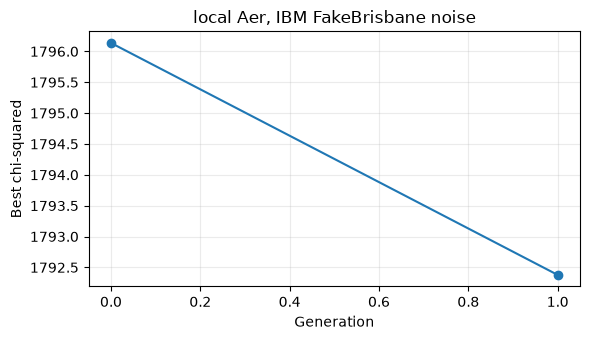

In [19]:
best_chi2 = np.array([entry[1] for entry in history], dtype=float)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(len(best_chi2)), best_chi2, marker="o")
ax.set(xlabel="Generation", ylabel="Best chi-squared", title=backend_label)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [17]:
print("Circuit executions:", executor.circuit_count)
print("Circuit-shots:", executor.circuit_count * SHOTS)
print("Cloud jobs:", executor.circuit_count if RUN_IONQ_CLOUD else 0)
if RUN_IONQ_CLOUD:
    print("IonQ job IDs:", executor.job_ids)
print("This is one optimizer trajectory, not an uncertainty estimate.")

Circuit executions: 4
Circuit-shots: 400
Cloud jobs: 0
This is one optimizer trajectory, not an uncertainty estimate.


In [18]:
# For a more stable comparison, increase GENERATIONS and repeat with independent seeds.
# Keep the backend label and circuit-shot budget alongside every result.

### Interpretation

The chart shows the best objective value after each AEQGA generation. The algorithm retains the best candidate, so this value should not increase. A one-generation, 100-shot run is a smoke test of the complete algorithm and noisy readout path; it does not establish convergence or a cosmological confidence interval. The local default uses IBM FakeBrisbane noise, not an IonQ device model.